In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt

simulator = AerSimulator()
shots = 100

print("Qiskit Fall Fest 2026")
print("Challenge 1: Predict the Output")
print("Simulator initialized successfully!")

Qiskit Fall Fest 2026
Challenge 1: Predict the Output
Simulator initialized successfully!


In [2]:
predictions = {
    "Circuit A": {"0": 0, "1": 100},
    "Circuit B": {"0": 100, "1": 0},
    "Circuit C": {"0": 50, "1": 50}
}

print("PREDICTIONS BEFORE EXECUTION")
print("-" * 45)

for circuit, prediction in predictions.items():
    print(f"{circuit}: {prediction}")

PREDICTIONS BEFORE EXECUTION
---------------------------------------------
Circuit A: {'0': 0, '1': 100}
Circuit B: {'0': 100, '1': 0}
Circuit C: {'0': 50, '1': 50}


Circuit A: One X Gate


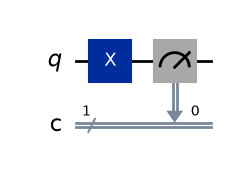

In [3]:
circuit_a = QuantumCircuit(1, 1)

circuit_a.x(0)
circuit_a.measure(0, 0)

print("Circuit A: One X Gate")
display(circuit_a.draw("mpl"))

Circuit B: Two X Gates


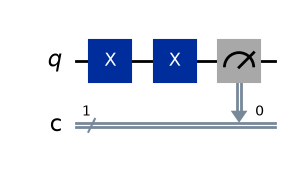

In [4]:
circuit_b = QuantumCircuit(1, 1)

circuit_b.x(0)
circuit_b.x(0)
circuit_b.measure(0, 0)

print("Circuit B: Two X Gates")
display(circuit_b.draw("mpl"))

Circuit C: Hadamard Gate


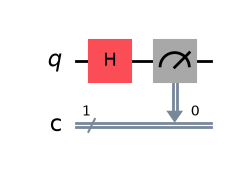

In [5]:
circuit_c = QuantumCircuit(1, 1)

circuit_c.h(0)
circuit_c.measure(0, 0)

print("Circuit C: Hadamard Gate")
display(circuit_c.draw("mpl"))

In [6]:
circuits = {
    "Circuit A": circuit_a,
    "Circuit B": circuit_b,
    "Circuit C": circuit_c
}

results = {}

for name, circuit in circuits.items():

    compiled = transpile(circuit, simulator)

    job = simulator.run(compiled, shots=100)

    result = job.result()

    counts = result.get_counts()

    results[name] = counts

    print(f"{name}: {counts}")

print("\nAll three circuits executed successfully!")

Circuit A: {'1': 100}
Circuit B: {'0': 100}
Circuit C: {'0': 48, '1': 52}

All three circuits executed successfully!



Circuit A Measurement Histogram


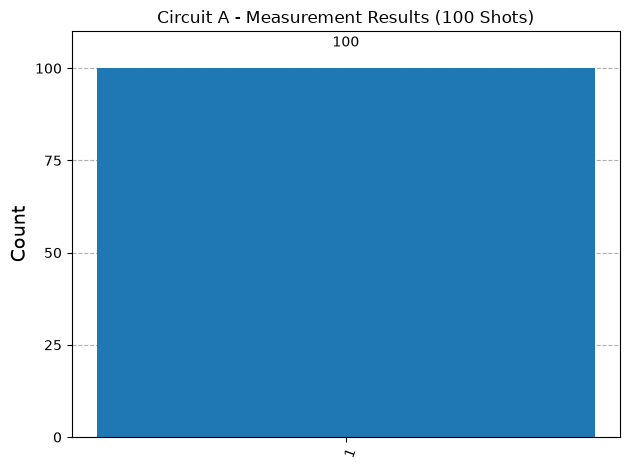


Circuit B Measurement Histogram


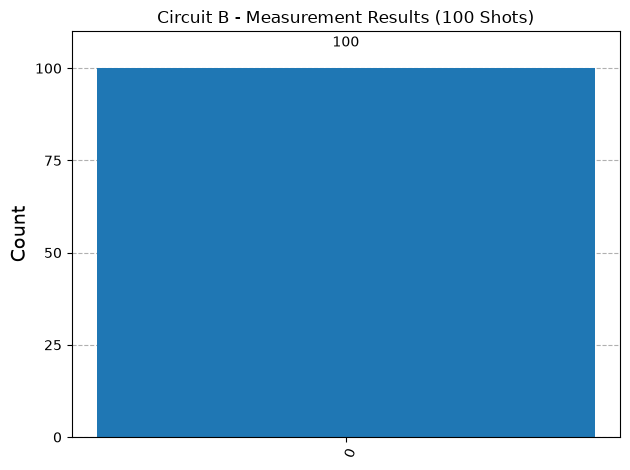


Circuit C Measurement Histogram


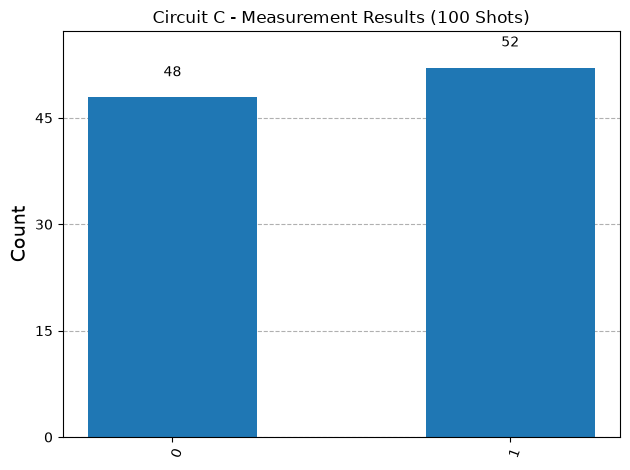

In [7]:
for name, counts in results.items():

    print(f"\n{name} Measurement Histogram")

    display(
        plot_histogram(
            counts,
            title=f"{name} - Measurement Results (100 Shots)",
            bar_labels=True
        )
    )

In [8]:
print("PREDICTION VS ACTUAL RESULTS")
print("=" * 75)

print(
    f"{'Circuit':<15}"
    f"{'Predicted 0':<15}"
    f"{'Predicted 1':<15}"
    f"{'Actual 0':<15}"
    f"{'Actual 1':<15}"
)

print("-" * 75)

for name in circuits:

    predicted = predictions[name]
    actual = results[name]

    print(
        f"{name:<15}"
        f"{predicted['0']:<15}"
        f"{predicted['1']:<15}"
        f"{actual.get('0', 0):<15}"
        f"{actual.get('1', 0):<15}"
    )

PREDICTION VS ACTUAL RESULTS
Circuit        Predicted 0    Predicted 1    Actual 0       Actual 1       
---------------------------------------------------------------------------
Circuit A      0              100            0              100            
Circuit B      100            0              100            0              
Circuit C      50             50             48             52             


In [9]:
print("CHALLENGE 1 VALIDATION")
print("=" * 50)

assert circuit_a.num_qubits == 1
assert circuit_b.num_qubits == 1
assert circuit_c.num_qubits == 1

for name, counts in results.items():
    assert sum(counts.values()) == 100, f"{name}: Invalid shot count"

assert results["Circuit A"].get("1", 0) == 100
assert results["Circuit B"].get("0", 0) == 100

print("PASS: All circuits use exactly one qubit.")
print("PASS: All circuits include measurement.")
print("PASS: Each circuit executed for 100 shots.")
print("PASS: Circuit A produced only state 1.")
print("PASS: Circuit B produced only state 0.")
print("PASS: Circuit C measurement results recorded.")

print("\nChallenge 1 validation completed successfully!")

CHALLENGE 1 VALIDATION
PASS: All circuits use exactly one qubit.
PASS: All circuits include measurement.
PASS: Each circuit executed for 100 shots.
PASS: Circuit A produced only state 1.
PASS: Circuit B produced only state 0.
PASS: Circuit C measurement results recorded.

Challenge 1 validation completed successfully!


## Challenge 1: Results and Conclusion

Circuit A — Single X Gate: The X gate changes the initial state \(|0\rangle\) into \(|1\rangle\). Therefore, all 100 measurements are expected to produce 1.

Circuit B — Two X Gates: Applying the X gate twice returns the qubit to its original state \(|0\rangle\). Therefore, all 100 measurements are expected to produce 0.

Circuit C — Hadamard Gate:** The Hadamard gate creates an equal superposition of \(|0\rangle\) and \(|1\rangle\). Each measurement has a 50% probability of producing either outcome. The actual counts may vary because of statistical randomness.

Conclusion: The simulation demonstrates that X gates produce deterministic results for computational-basis input states, while a Hadamard gate produces probabilistic measurement outcomes. The observed results can be compared with the theoretical predictions to understand the effects of quantum gates.